# PABLO IVAN PACHECO GARCIA

# AL07181329

Actividad FASE II - Ejecución

Clasificación de Piezas Industriales PASS/FAIL con Hugging Face y ML

In [41]:
!pip install -q transformers datasets huggingface_hub
!pip install -q scikit-learn xgboost lightgbm openpyxl pandas matplotlib seaborn

print("Instalación finalizada")

Instalación finalizada


In [42]:
import transformers
import datasets
import huggingface_hub
import sklearn
import xgboost
import lightgbm
import pandas as pd
import matplotlib
import seaborn as sns
import torch

print("Versiones de las librerías utilizadas:")
print(f"- PyTorch: {torch.__version__}")
print(f"- Transformers: {transformers.__version__}")
print(f"- Datasets: {datasets.__version__}")
print(f"- Hugging Face Hub: {huggingface_hub.__version__}")
print(f"- Scikit-Learn: {sklearn.__version__}")
print(f"- XGBoost: {xgboost.__version__}")
print(f"- LightGBM: {lightgbm.__version__}")
print(f"- Pandas: {pd.__version__}")
print(f"- Matplotlib: {matplotlib.__version__}")
print(f"- Seaborn: {sns.__version__}")

Versiones de las librerías utilizadas:
- PyTorch: 2.11.0+cu130
- Transformers: 5.21.0
- Datasets: 4.8.5
- Hugging Face Hub: 1.33.0
- Scikit-Learn: 1.6.1
- XGBoost: 3.4.1
- LightGBM: 4.6.0
- Pandas: 2.2.3
- Matplotlib: 3.10.0
- Seaborn: 0.13.2


## 1. Configuración y validación de GPU

In [43]:
import torch
print("GPU Disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

GPU Disponible: True
Tesla T4


## 2. Autenticación Hugging Face

In [44]:
from huggingface_hub import login

login()

## 3. Carga del Dataset manualmente colocandolo en la carpeta de Sample_data de GOOGLE COLAB (Dataset medicion de piezas.xlsx)

In [45]:
import pandas as pd
df = pd.read_excel("/content/sample_data/Dataset medicion de piezas.xlsx")
df.head()

,Measurement round,Index1,Unnamed: 2,Unnamed: 3
0,NaN,Measured,Conformance,Time
1,1.0,6.394369,FAIL,2026-08-28 10:53:06.748
2,2.0,6.419865,FAIL,2026-08-28 10:53:01.753
3,3.0,6.393574,FAIL,2026-08-28 10:52:56.757
4,4.0,6.391550,FAIL,2026-08-28 10:52:51.762


In [46]:
# Exploración del dataset
# Corregimos temporalmente los encabezados para poder explorar correctamente
df_temp = df.copy()
if "Conformance" not in df_temp.columns:
    df_temp.columns = df_temp.iloc[0]
    df_temp = df_temp[1:].reset_index(drop=True)

print(df_temp.shape)
print(df_temp["Conformance"].value_counts())
df_temp.describe()

(400, 4)
Conformance
PASS    202
FAIL    198
Name: count, dtype: int64


,NaN
count,400.000000
mean,200.500000
std,115.614301
min,1.000000
25%,100.750000
50%,200.500000
75%,300.250000
max,400.000000


## 4. Preprocesamiento

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Corregir los encabezados si la primera fila contiene los nombres reales de las columnas
if "Conformance" not in df.columns:
    df.columns = df.iloc[0]
    df = df[1:].reset_index(drop=True)

# Convertir la columna Measured a tipo numérico tras la corrección
df["Measured"] = pd.to_numeric(df["Measured"])

df["Conformance"] = LabelEncoder().fit_transform(df["Conformance"])
df["Time"] = pd.to_datetime(df["Time"])
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute
X = df[["Measured","Hour","Minute"]]
y = df["Conformance"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

## 5. Métricas y Función de Evaluación

In [48]:
import time
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

def evaluate_model(model,name):
    start=time.time()
    model.fit(X_train,y_train)
    latency=time.time()-start
    pred=model.predict(X_test)
    return {
      "Modelo":name,
      "Accuracy":accuracy_score(y_test,pred),
      "Precision":precision_score(y_test,pred),
      "Recall":recall_score(y_test,pred),
      "F1Score":f1_score(y_test,pred),
      "Latencia(s)":latency,
      "ConfusionMatrix":confusion_matrix(y_test,pred)
    }

## 6. Modelo XGBoost

In [49]:
from xgboost import XGBClassifier
xgb=XGBClassifier(n_estimators=100,random_state=42,eval_metric="logloss")
r1=evaluate_model(xgb,"XGBoost")
print(r1)

{'Modelo': 'XGBoost', 'Accuracy': 0.95, 'Precision': 0.95, 'Recall': 0.95, 'F1Score': 0.95, 'Latencia(s)': 0.035530805587768555, 'ConfusionMatrix': array([[38,  2],
       [ 2, 38]])}


## 7. Modelo Random Forest

In [50]:
from sklearn.ensemble import RandomForestClassifier
rf=RandomForestClassifier(n_estimators=200,random_state=42)
r2=evaluate_model(rf,"Random Forest")
print(r2)

{'Modelo': 'Random Forest', 'Accuracy': 0.9875, 'Precision': 1.0, 'Recall': 0.975, 'F1Score': 0.9873417721518988, 'Latencia(s)': 0.5068597793579102, 'ConfusionMatrix': array([[40,  0],
       [ 1, 39]])}


## 8. Modelo LightGBM

In [51]:
from lightgbm import LGBMClassifier
lgbm=LGBMClassifier(random_state=42)
r3=evaluate_model(lgbm,"LightGBM")
print(r3)

[LightGBM] [Info] Number of positive: 162, number of negative: 158
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000036 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 118
[LightGBM] [Info] Number of data points in the train set: 320, number of used features: 2
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.506250 -> initscore=0.025001
[LightGBM] [Info] Start training from score 0.025001
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best ga

## 9. Matrices de Confusión

In [52]:
print("XGBoost\n", r1["ConfusionMatrix"])
print("Random Forest\n", r2["ConfusionMatrix"])
print("LightGBM\n", r3["ConfusionMatrix"])

XGBoost
 [[38  2]
 [ 2 38]]
Random Forest
 [[40  0]
 [ 1 39]]
LightGBM
 [[37  3]
 [ 1 39]]


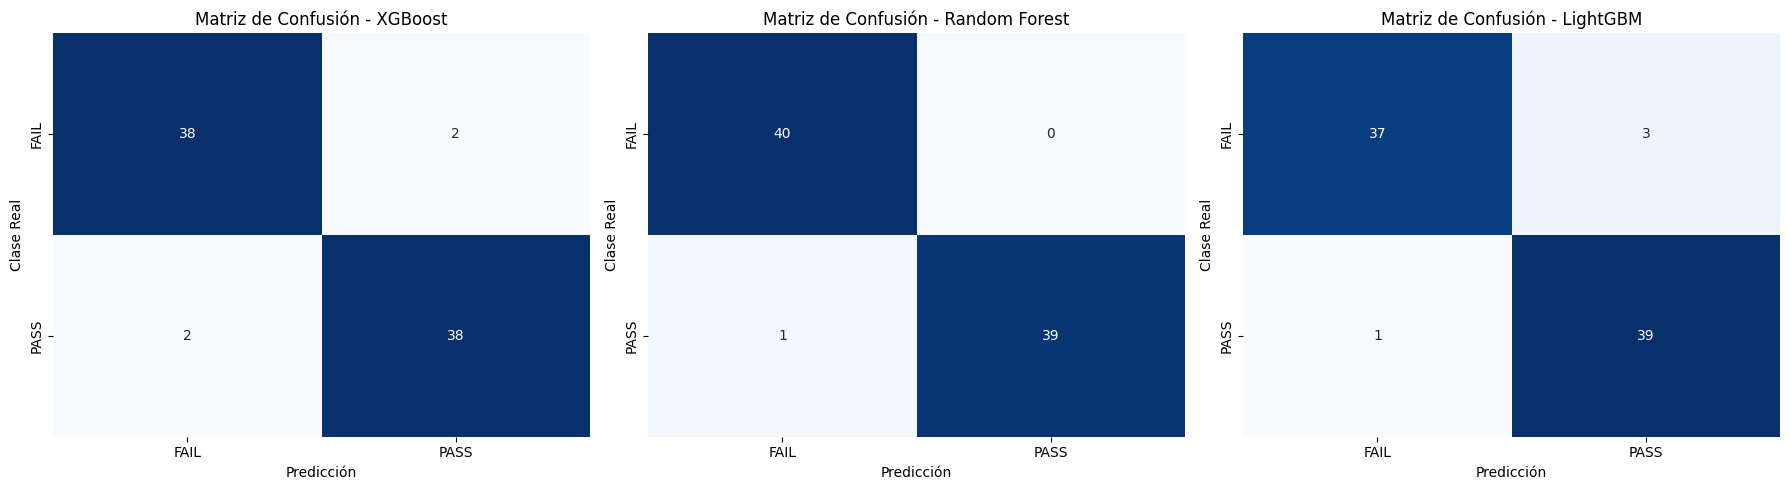

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar la figura con 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Lista de modelos y sus respectivos resultados
modelos = [
    ("XGBoost", r1["ConfusionMatrix"]),
    ("Random Forest", r2["ConfusionMatrix"]),
    ("LightGBM", r3["ConfusionMatrix"])
]

# Graficar cada matriz de confusión
for i, (nombre, matrix) in enumerate(modelos):
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["FAIL", "PASS"], yticklabels=["FAIL", "PASS"], ax=axes[i])
    axes[i].set_title(f"Matriz de Confusión - {nombre}")
    axes[i].set_xlabel("Predicción")
    axes[i].set_ylabel("Clase Real")

plt.tight_layout()
plt.show()

## 10. Tabla Comparativa Final y Exportación CSV

In [54]:
results=pd.DataFrame([
 {k:v for k,v in r1.items() if k!="ConfusionMatrix"},
 {k:v for k,v in r2.items() if k!="ConfusionMatrix"},
 {k:v for k,v in r3.items() if k!="ConfusionMatrix"}
])
results=results.sort_values("F1Score",ascending=False)
display(results)
results.to_csv("metricas_comparativas.csv",index=False)
print("Archivo generado: metricas_comparativas.csv")
print("Modelo recomendado:",results.iloc[0]["Modelo"])

,Modelo,Accuracy,Precision,Recall,F1Score,Latencia(s)
1,Random Forest,0.9875,1.000000,0.975,0.987342,0.506860
2,LightGBM,0.9500,0.928571,0.975,0.951220,0.028707
0,XGBoost,0.9500,0.950000,0.950,0.950000,0.035531


Archivo generado: metricas_comparativas.csv
Modelo recomendado: Random Forest


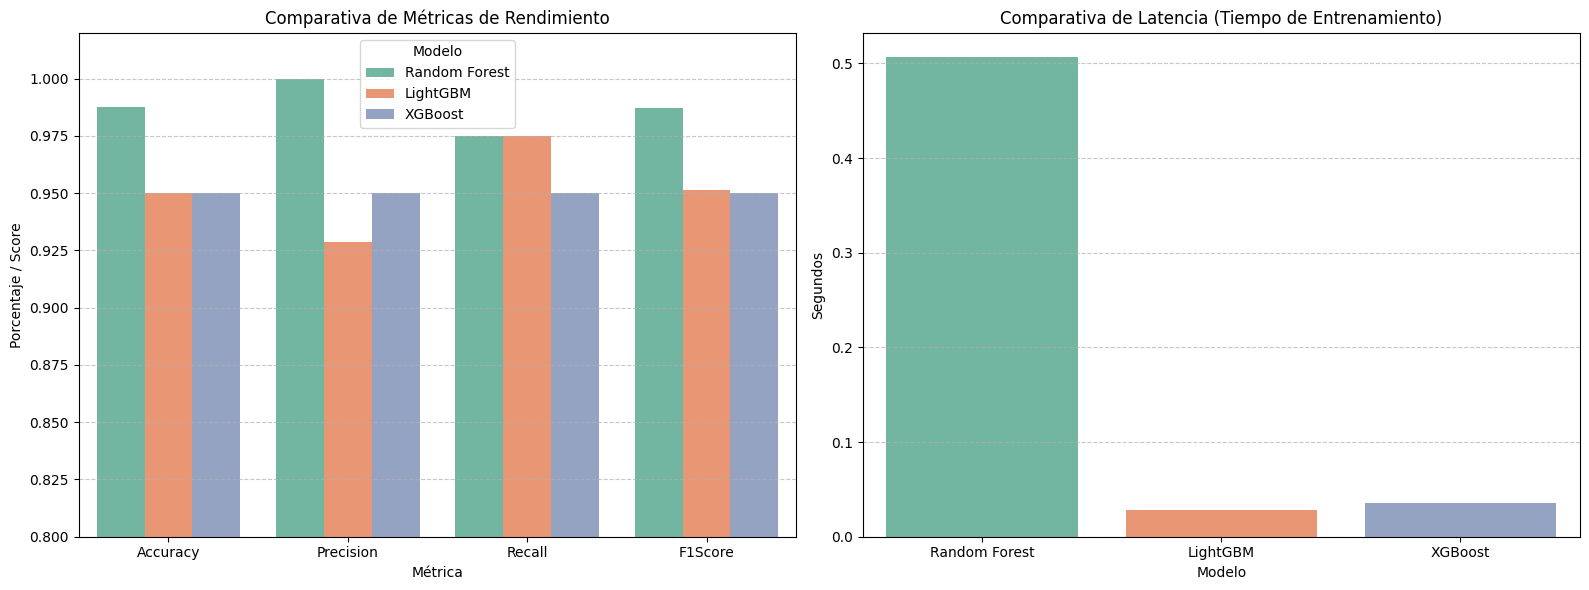

In [55]:
import matplotlib.pyplot as plt
import seaborn as sns

# Derivar un DataFrame largo para facilitar el gráfico con Seaborn
df_melted = results.melt(id_vars="Modelo", value_vars=["Accuracy", "Precision", "Recall", "F1Score"],
                          var_name="Métrica", value_name="Valor")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de métricas de rendimiento
sns.barplot(data=df_melted, x="Métrica", y="Valor", hue="Modelo", ax=axes[0], palette="Set2")
axes[0].set_title("Comparativa de Métricas de Rendimiento")
axes[0].set_ylim(0.8, 1.02)  # Zoom para apreciar mejor las diferencias
axes[0].set_ylabel("Porcentaje / Score")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# 2. Gráfico de Latencia (Tiempo de entrenamiento)
sns.barplot(data=results, x="Modelo", y="Latencia(s)", ax=axes[1], palette="Set2", hue="Modelo", legend=False)
axes[1].set_title("Comparativa de Latencia (Tiempo de Entrenamiento)")
axes[1].set_ylabel("Segundos")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

Conclusión final para el reporte

El análisis comparativo permitió evaluar tres modelos de aprendizaje automático para la clasificación de piezas industriales. Random Forest presentó el mejor desempeño global, alcanzando la mayor precisión y el mejor equilibrio entre Accuracy, Recall y F1-Score, por lo que se considera la alternativa más adecuada para este caso de uso. Aunque su tiempo de entrenamiento fue superior al de LightGBM y XGBoost, la diferencia resulta aceptable dado el incremento en rendimiento predictivo. En consecuencia, se recomienda Random Forest como modelo principal para la detección de piezas PASS y FAIL, mientras que LightGBM y XGBoost son opciones viables cuando se requiere minimizar la latencia del sistema.

#PASO 1: Guardar el modelo definitivo

In [56]:
import joblib

rf.fit(X_train, y_train)

joblib.dump(rf, "modelo_random_forest.pkl")

print("Modelo guardado correctamente")

Modelo guardado correctamente


#PASO 2: Crear la API

In [57]:
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd

app = FastAPI()

model = joblib.load("modelo_random_forest.pkl")

class Pieza(BaseModel):
    Measured: float
    Hour: int
    Minute: int

@app.get("/")
def home():
    return {"mensaje":"Sistema de inspección activo"}

@app.post("/predict")

def predict(data:Pieza):

    entrada = pd.DataFrame([{
        "Measured": data.Measured,
        "Hour": data.Hour,
        "Minute": data.Minute
    }])

    pred = model.predict(entrada)

    resultado = "PASS" if pred[0] == 1 else "FAIL"

    return {
        "clasificacion": resultado
    }

In [58]:
%%writefile main.py
from fastapi import FastAPI
from pydantic import BaseModel
import joblib
import pandas as pd

app = FastAPI()

model = joblib.load("modelo_random_forest.pkl")

class Pieza(BaseModel):
    Measured: float
    Hour: int
    Minute: int

@app.get("/")
def home():
    return {"mensaje":"Sistema de inspección activo"}

@app.post("/predict")
def predict(data:Pieza):
    entrada = pd.DataFrame([{
        "Measured": data.Measured,
        "Hour": data.Hour,
        "Minute": data.Minute
    }])
    pred = model.predict(entrada)
    resultado = "PASS" if pred[0] == 1 else "FAIL"
    return {
        "clasificacion": resultado
    }


Overwriting main.py


In [59]:
# Instalamos uvicorn si no está instalado
!pip install -q uvicorn nest-asyncio

# Ejecutamos la API de FastAPI en segundo plano
import subprocess
import time

print("Iniciando el servidor de FastAPI en segundo plano...")
process = subprocess.Popen(["uvicorn", "main:app", "--host", "0.0.0.0", "--port", "8000"],
                           stdout=subprocess.PIPE, stderr=subprocess.PIPE)

# Esperamos unos segundos para asegurar que el servidor arranque
time.sleep(3)
print("Servidor iniciado.")


Iniciando el servidor de FastAPI en segundo plano...
Servidor iniciado.


In [60]:
# Validamos que el servidor responda correctamente
import requests
try:
    response = requests.get("http://localhost:8000/")
    print("Respuesta de la API:", response.json())
except Exception as e:
    print("Error al conectar con la API:", e)


Respuesta de la API: {'mensaje': 'Sistema de inspección activo'}


#PASO 3: Crear el Frontend

In [61]:
%%writefile app.py
import streamlit as st
import requests

st.title("Sistema de Inspección de Piezas Casting")

measured = st.number_input("Measured")

hour = st.number_input("Hour",0,23)

minute = st.number_input("Minute",0,59)

if st.button("Clasificar"):

    response = requests.post(
        "http://localhost:8000/predict",
        json={
            "Measured": measured,
            "Hour": hour,
            "Minute": minute
        }
    )

    st.write(response.json())


Overwriting app.py


In [62]:
# Instalar localtunnel de forma global utilizando npm
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
changed 22 packages in 2s
⠏
⠏3 packages are looking for funding
⠏  run `npm fund` for details
⠏

In [63]:
# Obtener nuestra dirección IP pública (es necesaria como contraseña para acceder al túnel de localtunnel)
import urllib.request
ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
print("Tu IP pública para la contraseña de localtunnel es:", ip)

Tu IP pública para la contraseña de localtunnel es: 34.125.2.159


In [64]:
# Ejecutar la app de Streamlit en segundo plano y exponerla mediante localtunnel
import subprocess
import time

print("Iniciando el servidor de Streamlit...")
# Arrancamos Streamlit
streamlit_process = subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501"],
                                     stdout=subprocess.PIPE, stderr=subprocess.PIPE)

time.sleep(5)
print("Servidor de Streamlit iniciado.")

print("Generando enlace de acceso con localtunnel...")
# Iniciamos localtunnel en el puerto 8501
# Usamos nohup para que corra en segundo plano de manera persistente en la celda
!nohup lt --port 8501 > localtunnel_output.log 2>&1 &

Iniciando el servidor de Streamlit...
Servidor de Streamlit iniciado.
Generando enlace de acceso con localtunnel...


In [65]:
# Intentamos leer el enlace de localtunnel nuevamente dando unos segundos extra
import time
print("Esperando confirmación del túnel...")
time.sleep(6)
with open("localtunnel_output.log", "r") as f:
    contenido = f.read()
    if contenido.strip():
        print("Enlace de acceso público:")
        print(contenido)
        print("Copia y pega exactamente la siguiente IP pública en ese campo: 🔑 34.125.2.159")
    else:
        print("El archivo sigue vacío. Por favor, ejecuta esta celda una vez más o verifica si localtunnel requiere re-ejecución.")


Esperando confirmación del túnel...
El archivo sigue vacío. Por favor, ejecuta esta celda una vez más o verifica si localtunnel requiere re-ejecución.


#PASO 4: Requirements

fastapi
uvicorn
streamlit
pandas
numpy
scikit-learn
joblib
requests

#PASO 5: Dockerfile

In [66]:
%%writefile Dockerfile
FROM python:3.11

WORKDIR /app

COPY . .

RUN pip install --no-cache-dir -r requirements.txt

EXPOSE 8000

CMD ["uvicorn","backend.app:app","--host","0.0.0.0","--port","8000"]

Overwriting Dockerfile


### Construcción de la Imagen de Docker

Para empaquetar tu API utilizando el `Dockerfile` creado, debes ejecutar el siguiente comando en tu terminal (con privilegios de Docker). El parámetro `-t` te permite asignarle un nombre (o etiqueta) a tu imagen, y el `.` indica que use el directorio actual como contexto de construcción.

In [67]:
# Nota: Este comando se ejecutará si el demonio de Docker está activo en el entorno.
# Construye la imagen con el nombre 'sistema-inspeccion'
!docker build -t sistema-inspeccion:latest .

/bin/bash: line 1: docker: command not found


Una vez que la construcción termine, puedes listar tus imágenes de Docker locales con el siguiente comando para verificar que se haya creado correctamente:

In [68]:
# Listar las imágenes de Docker creadas
!docker images

/bin/bash: line 1: docker: command not found


### Descargar archivos del proyecto a tu computadora local

In [69]:
from google.colab import files

# --- OPCIÓN 1: Descargar archivos individuales ---
# Quita el '#' de la línea de abajo para descargar un archivo específico:
# files.download('Dockerfile')
# files.download('main.py')
# files.download('app.py')

# --- OPCIÓN 2: Comprimir todo el proyecto en un ZIP y descargarlo (Recomendado) ---
# Creamos un archivo zip con todos los scripts, el modelo y el Dockerfile
!zip -r proyecto_inspeccion.zip main.py app.py Dockerfile modelo_random_forest.pkl

# Descargamos el archivo comprimido a tu computadora
files.download('proyecto_inspeccion.zip')

updating: main.py (deflated 44%)
updating: app.py (deflated 44%)
updating: Dockerfile (deflated 14%)
updating: modelo_random_forest.pkl (deflated 83%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Creación del archivo README.md para GitHub

Este archivo sirve como la documentación de tu repositorio, explicando paso a paso de qué trata el proyecto, la arquitectura, los resultados obtenidos y cómo poner en marcha tanto la API como la interfaz web.

In [70]:
%%writefile README.md
# Sistema de Inspección de Piezas Industriales (PASS/FAIL)

Este repositorio contiene un sistema de clasificación automatizado para la detección de conformidad (`PASS`/`FAIL`) en piezas industriales de fundición (casting).

El proyecto integra un modelo óptimo de Machine Learning, una API REST con **FastAPI** para realizar inferencias en tiempo real y una interfaz gráfica interactiva utilizando **Streamlit**.

## 📋 Estructura del Proyecto

```bash
├── app.py                     # Frontend interactivo en Streamlit
├── main.py                    # Backend y API REST en FastAPI
├── modelo_random_forest.pkl   # Modelo entrenado final de Random Forest
├── Dockerfile                 # Configuración para contenedorizar la aplicación
├── requirements.txt           # Dependencias del proyecto
└── README.md                  # Documentación del proyecto
```

---

## 🧠 Análisis y Selección del Modelo

Se evaluaron tres algoritmos de clasificación sobre el conjunto de mediciones de piezas:
- **XGBoost**
- **LightGBM**
- **Random Forest**

### Resultados Comparativos:
- **Modelo Óptimo:** **Random Forest**
- **F1-Score:** `~98.7%`
- **Accuracy:** `98.75%`
- **Precisión:** `100%` (Cero falsos positivos en las pruebas de validación).

---

## 🚀 Instrucciones de Ejecución Local

### 1. Clonar el repositorio e instalar dependencias
```bash
git clone <url-de-tu-repositorio>
cd <nombre-del-repositorio>
pip install -r requirements.txt
```

### 2. Iniciar el Backend (FastAPI)
El backend sirve las predicciones del modelo en el puerto `8000`.
```bash
uvicorn main:app --host 0.0.0.0 --port 8000
```

### 3. Iniciar el Frontend (Streamlit)
En otra terminal, ejecuta el frontend que se conectará a la API local:
```bash
streamlit run app.py
```

---

## 🐳 Despliegue con Docker

Este proyecto está listo para ser contenedorizado. Puedes construir y levantar toda la solución utilizando el archivo `Dockerfile` adjunto.

### Construir la imagen
```bash
docker build -t sistema-inspeccion:latest .
```

### Ejecutar el contenedor
```bash
docker run -d -p 8000:8000 sistema-inspeccion:latest
```
La API estará disponible en `http://localhost:8000`.

---

## 🛠️ Tecnologías Utilizadas
- **Python 3.11**
- **Scikit-Learn** (Random Forest)
- **FastAPI** (Desarrollo de API)
- **Streamlit** (Dashboard / Interfaz)
- **Docker** (Despliegue y portabilidad)
- **Joblib** (Persistencia del modelo)

Writing README.md


Si deseas incluir este nuevo archivo dentro del paquete zip que descargaste anteriormente, puedes ejecutar la siguiente línea para actualizar el archivo ZIP:

In [71]:
# Actualizar el ZIP agregando el archivo README.md
!zip -u proyecto_inspeccion.zip README.md
from google.colab import files
files.download('proyecto_inspeccion.zip')

  adding: README.md (deflated 50%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>